# 02. Pipeline Phân chia 3 Tập Chống Rò rỉ & Chuẩn hóa RobustScaler
### Đề tài 13: Credit Card Fraud Detection (Unsupervised Anomaly Detection)
* **Học phần:** Khai phá Dữ liệu (Data Mining) — PTIT
* **Sinh viên thực hiện:** 
  * Nguyễn Văn Hiển Vinh (B23DCVT461) — *Leader / Data & Preprocessing Lead*
  * Nguyễn Minh Hoàng (B23DCVT173) — *Modeling & Evaluation Lead*
* **Kế hoạch thực hiện:** Phase 2 (Sprint Ngày 4) theo Kế hoạch V2.1
* **Mục tiêu kỹ thuật cốt lõi:**
  1. Thực hiện phân chia phân tầng (Stratified Split 70/15/15) chống rò rỉ dữ liệu (Zero-Leakage).
  2. Tách riêng 199.020 mẫu Normal (`Train_Normal`) phục vụ huấn luyện Học không giám sát (Novelty Detection); loại bỏ 344 mẫu Fraud ở vùng Train khỏi quá trình fit.
  3. Bảo toàn tỷ lệ gian lận tự nhiên ở Validation Set (42.721 mẫu, 74 Fraud ~ 0.1732%) và Test Set (42.722 mẫu, 74 Fraud ~ 0.1732%).
  4. Chuẩn hóa đặc trưng `Amount` và `Time` bằng `RobustScaler` (fit DUY NHẤT trên `Train_Normal`), giữ nguyên 28 biến $V_1 \dots V_{28}$.
  5. Xuất biểu đồ kiểm chứng phân phối `05_preprocessing_scaling_check.png` lưu vào `reports/figures/`.
  6. Đóng gói dữ liệu sạch vào thư mục `data/processed/` sẵn sàng bàn giao cho các notebook huấn luyện mô hình ở Phase 3, 4, 5.


In [1]:
# ==============================================================================
# BƯỚC 1: KHỞI TẠO MÔI TRƯỜNG & NẠP MODULE TÁI SỬ DỤNG TỪ SRC/
# ==============================================================================
# GIẢNG VIÊN HỎI: Bạn tổ chức cấu trúc mã nguồn ở đây như thế nào?
# BẠN TRẢ LỜI:
# - Toàn bộ logic lõi về nạp/chia dữ liệu (src.data_loader) và tiền xử lý (src.preprocessor)
#   đã được nhóm đóng gói chuẩn mực thành các Python modules độc lập trong thư mục src/.
# - Notebook này đóng vai trò là môi trường thực nghiệm: gọi các hàm từ src/ ra chạy,
#   in bảng đối soát và vẽ đồ thị kiểm chứng để thầy cô nghiệm thu.

import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Thiết lập đường dẫn gốc project
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Nạp các tham số cố định và module chuẩn mực từ src/
from src.config import RAW_DATA_PATH, PROCESSED_DATA_DIR, FIGURES_DIR, RANDOM_STATE
from src.data_loader import load_raw_data, split_data_zero_leakage
from src.preprocessor import ZeroLeakagePreprocessor

# Cấu hình đồ họa chuẩn IEEE
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
sns.set_theme(style="whitegrid", palette="muted")
np.random.seed(RANDOM_STATE)

# Đảm bảo thư mục lưu trữ tồn tại
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"[OK] Setup hoàn tất! Seed={RANDOM_STATE}")
print(f"[OK] Thư mục dữ liệu sạch: {PROCESSED_DATA_DIR}")
print(f"[OK] Thư mục biểu đồ: {FIGURES_DIR}")


[OK] Setup hoàn tất! Seed=42
[OK] Thư mục dữ liệu sạch: C:\Users\Vinh Nguyen\DATAMINING\data\processed
[OK] Thư mục biểu đồ: C:\Users\Vinh Nguyen\DATAMINING\reports\figures


---
## 1. Thực thi Phân chia 3 Tập Phân tầng (Stratified 3-Way Split)
### Nguyên tắc Zero-Leakage (Không rò rỉ dữ liệu):
1. **Chia 2 bước có phân tầng (`stratify=Class`):** 
   - Bước 1: 70% Train Partition (199.364 dòng) vs 30% Temp Partition (85.443 dòng).
   - Bước 2: Chia đôi 30% Temp thành 15% Validation (42.721 dòng) và 15% Test (42.722 dòng).
2. **Quy tắc Novelty Detection:** 
   - Trong 199.364 dòng của Train Partition, có 344 dòng Fraud. Ta **loại bỏ 344 dòng Fraud này**, chỉ giữ lại đúng **199.020 dòng Normal (`Train_Normal`)** để huấn luyện mô hình.
   - Nhờ đó, mô hình học thuần khiết thói quen của người bình thường mà không bị rò rỉ nhãn gian lận.


In [2]:
# ==============================================================================
# BƯỚC 2: PHÂN CHIA DỮ LIỆU THÀNH 3 HỘP ĐỘC LẬP (TRAIN / VALIDATION / TEST)
# ==============================================================================
# GIẢNG VIÊN HỎI: Tại sao không dồn 344 mẫu Fraud ở Train sang Validation để tăng mẫu test?
# BẠN TRẢ LỜI:
# - Nếu tự ý chuyển 344 Fraud sang Val/Test, tỷ lệ gian lận ở Val/Test sẽ bị thổi phồng lên ~0.573%
#   (gấp hơn 3 lần phân phối thực tế 0.172%). Điều đó làm sai lệch phân phối thực tế!
# - Phương án khoa học đúng đắn là: Giữ nguyên tỷ lệ phân tầng tự nhiên ở Val và Test (~0.1732%),
#   còn 344 mẫu Fraud trong vùng Train bị loại bỏ hoàn toàn khỏi việc fit mô hình để tuân thủ
#   nguyên tắc Unsupervised Novelty Detection (chỉ dạy máy tính thói quen người tốt).

# 1. Nạp dataset gốc 284.807 dòng
raw_df = load_raw_data(RAW_DATA_PATH)

# 2. Gọi hàm phân chia Zero-Leakage đã đóng gói trong src/data_loader.py
train_df, val_df, test_df = split_data_zero_leakage(raw_df, random_state=RANDOM_STATE)

print("\n-> Phân chia hoàn tất!")
print(f"   Train_Normal shape : {train_df.shape} (100% Class 0 - Dùng để học)")
print(f"   Validation shape   : {val_df.shape} (Có {val_df['Class'].sum()} Fraud - Dùng thi thử & chọn ngưỡng)")
print(f"   Test Set shape     : {test_df.shape} (Có {test_df['Class'].sum()} Fraud - NIÊM PHONG ĐẾN NGÀY 12)")


XÁC NHẬN PHÂN CHIA DỮ LIỆU ZERO-LEAKAGE (CHUẨN V2.1):
1. Tổng dữ liệu gốc : 284,807 mẫu (284,315 Normal + 492 Fraud)
2. Phân vùng Train   : 199,364 mẫu (344 Fraud bị loại bỏ khỏi huấn luyện)
   -> Train_Normal   : 199,020 mẫu (Chỉ chứa Class 0, dùng fit scaler & model)
3. Tập Validation    : 42,721 mẫu (74 Fraud ~ 0.1732%)
4. Tập Test Set      : 42,722 mẫu (74 Fraud ~ 0.1732%) [NIÊM PHONG]

-> Phân chia hoàn tất!
   Train_Normal shape : (199020, 31) (100% Class 0 - Dùng để học)
   Validation shape   : (42721, 31) (Có 74 Fraud - Dùng thi thử & chọn ngưỡng)
   Test Set shape     : (42722, 31) (Có 74 Fraud - NIÊM PHONG ĐẾN NGÀY 12)


---
## 2. Bảng Đối soát & Kiểm kê Toàn vẹn Dữ liệu (Sanity Check Table)
Chúng ta lập bảng đối soát chi tiết để chứng minh tính nhất quán số học $100\%$ trước Giảng viên:
* Tổng số dòng gốc: $284.807$
* Tổng số Fraud gốc: $492$ ($344$ trong Train Partition bị loại khỏi fit + $74$ trong Val + $74$ trong Test).


In [3]:
# ==============================================================================
# BẢNG ĐỐI SOÁT KIỂM KÊ DỮ LIỆU TRƯỚC HỘI ĐỒNG (SANITY CHECK)
# ==============================================================================
# GIẢNG VIÊN HỎI: Bảng này dùng để làm gì?
# BẠN TRẢ LỜI:
# - Bảng này chứng minh tính bảo toàn số học: Toàn bộ 284.807 dòng và 492 mẫu gian lận
#   được phân bổ minh bạch, không bị thất thoát hoặc tự ý làm sai lệch số liệu.

split_summary = pd.DataFrame({
    'Tên phân vùng': [
        'Train_Normal (Dùng huấn luyện)',
        'Train_Fraud (Loại bỏ khỏi fit)',
        'Validation Set (Thẩm định & Ngưỡng)',
        'Test Set (Kiểm thử độc lập - Niêm phong)'
    ],
    'Số mẫu Normal (Class 0)': [
        len(train_df),
        0,
        (val_df['Class'] == 0).sum(),
        (test_df['Class'] == 0).sum()
    ],
    'Số mẫu Fraud (Class 1)': [
        0,
        344,
        (val_df['Class'] == 1).sum(),
        (test_df['Class'] == 1).sum()
    ],
    'Tổng số mẫu': [
        len(train_df),
        344,
        len(val_df),
        len(test_df)
    ],
    'Tỷ lệ Fraud (%)': [
        f"{0.0:.4f}%",
        f"{100.0:.4f}%",
        f"{(val_df['Class'].sum() / len(val_df)) * 100:.4f}%",
        f"{(test_df['Class'].sum() / len(test_df)) * 100:.4f}%"
    ]
})

print("=" * 90)
print("BẢNG ĐỐI SOÁT PHÂN CHIA DỮ LIỆU ZERO-LEAKAGE (CHUẨN V2.1):")
print(split_summary.to_string(index=False))
print("=" * 90)

# Kiểm tra toán học tự động (Assertion Checks)
total_normal_check = split_summary['Số mẫu Normal (Class 0)'].sum()
total_fraud_check = split_summary['Số mẫu Fraud (Class 1)'].sum()
total_samples_check = split_summary['Tổng số mẫu'].sum()

assert total_samples_check == 284807, f"Sai lệch tổng số mẫu: {total_samples_check}"
assert total_normal_check == 284315, f"Sai lệch số mẫu Normal: {total_normal_check}"
assert total_fraud_check == 492, f"Sai lệch số mẫu Fraud: {total_fraud_check}"
print("=> [XÁC NHẬN TOÁN HỌC PASS]: Tổng số mẫu khớp 284.807 dòng, 492 Fraud, không mất mát bất kỳ dòng nào!")


BẢNG ĐỐI SOÁT PHÂN CHIA DỮ LIỆU ZERO-LEAKAGE (CHUẨN V2.1):
                           Tên phân vùng  Số mẫu Normal (Class 0)  Số mẫu Fraud (Class 1)  Tổng số mẫu Tỷ lệ Fraud (%)
          Train_Normal (Dùng huấn luyện)                   199020                       0       199020         0.0000%
          Train_Fraud (Loại bỏ khỏi fit)                        0                     344          344       100.0000%
     Validation Set (Thẩm định & Ngưỡng)                    42647                      74        42721         0.1732%
Test Set (Kiểm thử độc lập - Niêm phong)                    42648                      74        42722         0.1732%
=> [XÁC NHẬN TOÁN HỌC PASS]: Tổng số mẫu khớp 284.807 dòng, 492 Fraud, không mất mát bất kỳ dòng nào!


---
## 3. Tiền xử lý Dữ liệu bằng RobustScaler (Zero-Leakage Preprocessing)
### Cơ sở Toán học:
$$x_{\text{scaled}} = \frac{x - Q_2(x)}{\text{IQR}(x)} = \frac{x - \text{Median}(x)}{Q_3(x) - Q_1(x)}$$

* **Tại sao chỉ fit trên `Train_Normal`?**
  * Để ngăn chặn hoàn toàn rò rỉ thông tin (Data Leakage / Data Snooping). Ta không cho phép các phân phối của tập Validation hay Test can thiệp vào việc tính Median và IQR.
* **Tại sao giữ nguyên $V_1 \dots V_{28}$?**
  * 28 biến này đã được ngân hàng biến đổi PCA tiêu chuẩn với kỳ vọng $\sim 0$. Ta giữ nguyên dạng để không phá vỡ trật tự phương sai giải thích.


In [4]:
# ==============================================================================
# BƯỚC 3: CHUẨN HÓA ĐẶC TRƯNG BẰNG ROBUSTSCALER (ÉP CÂN THU NHỎ SỐ TIỀN & THỜI GIAN)
# ==============================================================================
# GIẢNG VIÊN HỎI: Chuẩn hóa để làm gì? Và tại sao dùng RobustScaler mà không dùng StandardScaler hay MinMaxScaler?
# BẠN TRẢ LỜI:
# 1. CHUẨN HÓA ĐỂ LÀM GÌ:
#    - Cột Amount lên tới 25.000 USD, Time lên tới 170.000 giây, trong khi 28 cột V chỉ dao động từ -3 đến +3.
#    - Cả 3 mô hình (iForest, LOF, One-Class SVM) đều dựa trên khoảng cách hình học để tìm ngoại lai.
#    - Nếu không chuẩn hóa, khoảng cách sẽ bị cột Amount và Time chi phối 99.9%, làm tê liệt 28 biến V!
#    - Chuẩn hóa giúp đưa 30 đặc trưng về cùng một thang đo tương đương nhau để đối xử công bằng.
# 2. TẠI SAO DÙNG ROBUSTSCALER:
#    - StandardScaler dùng Trung bình (Mean) và Độ lệch chuẩn (Std) -> bị các khoản tiền khổng lồ (25.000 USD)
#      kéo lệch, nén 99% giao dịch nhỏ về sát 0.
#    - MinMaxScaler càng tệ vì bị ép chặt bởi giá trị Max.
#    - RobustScaler dùng Trung vị (Median) và IQR (Q3 - Q1) -> Hoàn toàn MIỄN NHIỄM với các khoản tiền ngoại lai cực đoan!

# 1. Khởi tạo đối tượng tiền xử lý từ module src/preprocessor.py
preprocessor = ZeroLeakagePreprocessor()

# 2. FIT DUY NHẤT trên tập Train_Normal (Chỉ học Median và IQR của người bình thường)
preprocessor.fit(train_df)

# In các tham số thống kê đã học được từ Train
med_amount = preprocessor.scaler_amount.center_[0]
iqr_amount = preprocessor.scaler_amount.scale_[0]
med_time = preprocessor.scaler_time.center_[0]
iqr_time = preprocessor.scaler_time.scale_[0]

print("=" * 60)
print("THAM SỐ HỌC ĐƯỢC TỪ TẬP HUẤN LUYỆN (TRAIN_NORMAL):")
print(f"-> Amount : Median = {med_amount:.2f} USD, IQR = {iqr_amount:.2f} USD")
print(f"-> Time   : Median = {med_time:.2f} s, IQR = {iqr_time:.2f} s")
print("=" * 60)

# 3. TRANSFORM sang cả 3 tập (Áp dụng Median/IQR đã học sang Val và Test)
X_train, y_train = preprocessor.transform(train_df)
X_val, y_val = preprocessor.transform(val_df)
X_test, y_test = preprocessor.transform(test_df)

print("\n-> Ma trận đặc trưng sau chuẩn hóa (30 cột: 28 biến V + 2 biến scaled):")
print(f"   X_train shape : {X_train.shape} | Nhãn y_train: {len(y_train):,} mẫu (100% là 0)")
print(f"   X_val shape   : {X_val.shape} | Nhãn y_val  : {len(y_val):,} mẫu ({y_val.sum()} Fraud)")
print(f"   X_test shape  : {X_test.shape} | Nhãn y_test : {len(y_test):,} mẫu ({y_test.sum()} Fraud)")


THAM SỐ HỌC ĐƯỢC TỪ TẬP HUẤN LUYỆN (TRAIN_NORMAL):
-> Amount : Median = 22.00 USD, IQR = 71.73 USD
-> Time   : Median = 84850.50 s, IQR = 85103.00 s



-> Ma trận đặc trưng sau chuẩn hóa (30 cột: 28 biến V + 2 biến scaled):
   X_train shape : (199020, 30) | Nhãn y_train: 199,020 mẫu (100% là 0)
   X_val shape   : (42721, 30) | Nhãn y_val  : 42,721 mẫu (74 Fraud)
   X_test shape  : (42722, 30) | Nhãn y_test : 42,722 mẫu (74 Fraud)


---
## 4. Trực quan hóa Đối chứng Trước & Sau khi Chuẩn hóa RobustScaler
Ta vẽ biểu đồ kiểm chứng phân phối của `Amount` và `Time`:
* Trước khi scale: `Amount` có đuôi kéo dài tới $25.000$ USD, `Time` đo bằng giây từ $0$ đến $172.000$ giây.
* Sau khi scale: `scaled_amount` và `scaled_time` có trung vị nằm tại $0$, khoảng tứ phân vị IQR nằm chuẩn trong đoạn $[-0.5, +0.5]$, không còn làm lấn át 28 biến PCA $V_1 \dots V_{28}$.


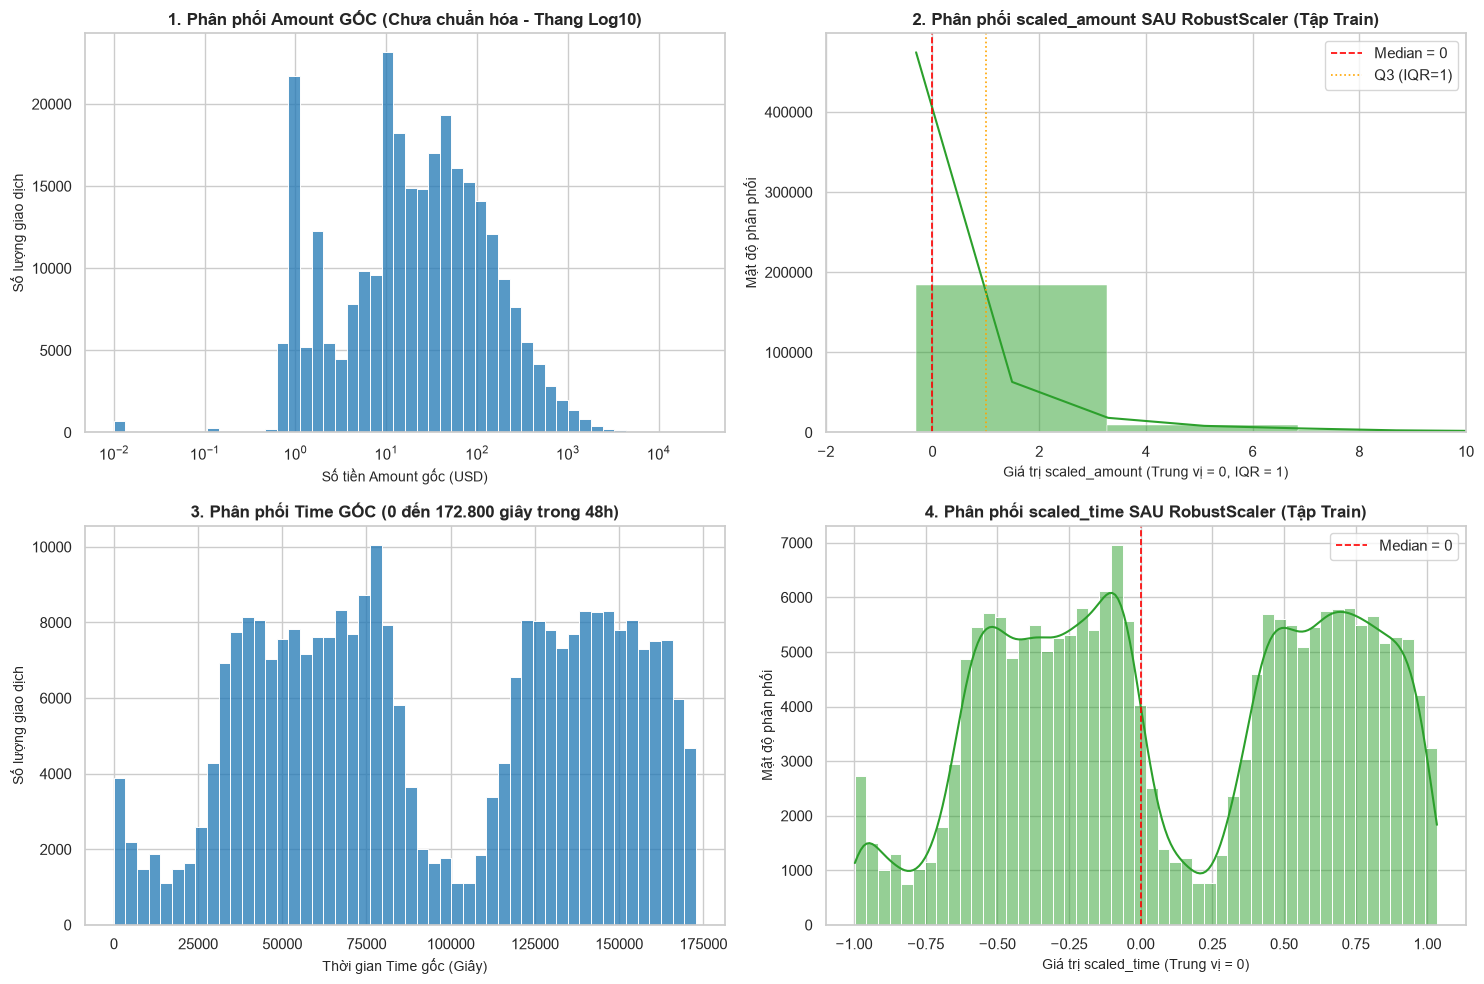

[ĐÃ XUẤT ẢNH] Lưu biểu đồ kiểm chứng thành công tại: C:\Users\Vinh Nguyen\DATAMINING\reports\figures\05_preprocessing_scaling_check.png


In [5]:
# ==============================================================================
# VẼ BIỂU ĐỒ KIỂM CHỨNG: ĐỐI CHỨNG TRƯỚC VÀ SAU KHI SCALE (4 SUBPLOTS)
# ==============================================================================
# GIẢNG VIÊN HỎI: Biểu đồ này chứng minh điều gì?
# BẠN TRẢ LỜI:
# - Biểu đồ này chứng minh thuật toán RobustScaler đã co cụm phân phối số tiền quẹt thẻ
#   từ một dải cực rộng (0 đến 25.000 USD) về nằm gọn gàng quanh mốc Median = 0 và IQR = 1,
#   loại bỏ nguy cơ làm méo mó các mô hình học máy.

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Subplot 1: Phân phối Amount gốc (Thang Log10 để quan sát ngoại lai)
sns.histplot(
    data=raw_df, x='Amount', bins=50, log_scale=True,
    color='#1f77b4', kde=False, ax=axes[0, 0]
)
axes[0, 0].set_title('1. Phân phối Amount GỐC (Chưa chuẩn hóa - Thang Log10)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Số tiền Amount gốc (USD)', fontsize=10)
axes[0, 0].set_ylabel('Số lượng giao dịch', fontsize=10)

# Subplot 2: Phân phối scaled_amount sau RobustScaler (Zoom vùng [-2, 10])
sns.histplot(
    data=X_train, x='scaled_amount', bins=100,
    color='#2ca02c', kde=True, ax=axes[0, 1]
)
axes[0, 1].set_xlim(-2, 10)
axes[0, 1].axvline(0, color='red', linestyle='--', linewidth=1.2, label='Median = 0')
axes[0, 1].axvline(1, color='orange', linestyle=':', linewidth=1.2, label='Q3 (IQR=1)')
axes[0, 1].set_title('2. Phân phối scaled_amount SAU RobustScaler (Tập Train)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Giá trị scaled_amount (Trung vị = 0, IQR = 1)', fontsize=10)
axes[0, 1].set_ylabel('Mật độ phân phối', fontsize=10)
axes[0, 1].legend()

# Subplot 3: Phân phối Time gốc (0 đến 172.800 giây)
sns.histplot(
    data=raw_df, x='Time', bins=50,
    color='#1f77b4', kde=False, ax=axes[1, 0]
)
axes[1, 0].set_title('3. Phân phối Time GỐC (0 đến 172.800 giây trong 48h)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Thời gian Time gốc (Giây)', fontsize=10)
axes[1, 0].set_ylabel('Số lượng giao dịch', fontsize=10)

# Subplot 4: Phân phối scaled_time sau RobustScaler
sns.histplot(
    data=X_train, x='scaled_time', bins=50,
    color='#2ca02c', kde=True, ax=axes[1, 1]
)
axes[1, 1].axvline(0, color='red', linestyle='--', linewidth=1.2, label='Median = 0')
axes[1, 1].set_title('4. Phân phối scaled_time SAU RobustScaler (Tập Train)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Giá trị scaled_time (Trung vị = 0)', fontsize=10)
axes[1, 1].set_ylabel('Mật độ phân phối', fontsize=10)
axes[1, 1].legend()

plt.tight_layout()
fig5_path = FIGURES_DIR / "05_preprocessing_scaling_check.png"
plt.savefig(fig5_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[ĐÃ XUẤT ẢNH] Lưu biểu đồ kiểm chứng thành công tại: {fig5_path}")


---
## 5. Kiểm tra Giá trị NaN & Inf trước khi Đóng gói
Đảm bảo các ma trận đầu ra không chứa bất kỳ giá trị `NaN` (khuyết thiếu) hoặc `Inf` (vô cực) nào để các thuật toán máy học ở Phase 3, 4, 5 chạy trơn tru tuyệt đối.


In [6]:
# ==============================================================================
# BƯỚC 4: KIỂM TRA CHỐT CHẶN AN TOÀN (SANITY CHECK CHO NAN VÀ INF)
# ==============================================================================
# GIẢNG VIÊN HỎI: Kiểm tra giá trị NaN và Inf ở đây để làm gì?
# BẠN TRẢ LỜI:
# - NaN là giá trị khuyết thiếu; Inf là giá trị vô cực (thường sinh ra do phép chia cho 0).
# - Cả 3 thư viện Isolation Forest, LOF và One-Class SVM của scikit-learn sẽ lập tức
#   BỊ SẬP (Crash / Throw Exception) nếu ma trận đầu vào chứa dù chỉ 1 giá trị NaN hoặc Inf!
# - Bước kiểm tra này là chốt chặn an toàn bắt buộc, chứng minh dữ liệu sau khi scale
#   hoàn toàn sạch sẽ 100%, sẵn sàng cho quá trình huấn luyện máy học.

nan_train = np.isnan(X_train.values).sum()
nan_val = np.isnan(X_val.values).sum()
nan_test = np.isnan(X_test.values).sum()

inf_train = np.isinf(X_train.values).sum()
inf_val = np.isinf(X_val.values).sum()
inf_test = np.isinf(X_test.values).sum()

print("=" * 60)
print(f"Kiểm tra NaN (Ô trống) : Train={nan_train}, Val={nan_val}, Test={nan_test}")
print(f"Kiểm tra Inf (Vô cực)  : Train={inf_train}, Val={inf_val}, Test={inf_test}")
assert (nan_train + nan_val + nan_test) == 0, "[LỖI] Xuất hiện giá trị NaN!"
assert (inf_train + inf_val + inf_test) == 0, "[LỖI] Xuất hiện giá trị Inf!"
print("=> [HOÀN HẢO] Dữ liệu hoàn toàn sạch, không có NaN hoặc Inf!")
print("=" * 60)


Kiểm tra NaN (Ô trống) : Train=0, Val=0, Test=0
Kiểm tra Inf (Vô cực)  : Train=0, Val=0, Test=0
=> [HOÀN HẢO] Dữ liệu hoàn toàn sạch, không có NaN hoặc Inf!


---
## 6. Đóng gói & Lưu trữ Dữ liệu Sạch vào `data/processed/`
Để các notebook tiếp theo (`03_isolation_forest.ipynb`, `04_local_outlier_factor.ipynb`, `05_one_class_svm.ipynb`) không phải chạy lại bước tiền xử lý, ta lưu trữ dữ liệu sạch bằng định dạng nén `.npz` và `.csv.gz`.
* File `creditcard_preprocessed.npz`: Chứa toàn bộ mảng `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, `y_test`. Nạp lại chỉ mất $0.2$ giây!
* File `preprocessor.joblib`: Lưu bộ `ZeroLeakagePreprocessor` đã fit trên `Train_Normal` (Median, IQR và thứ tự 30 đặc trưng).


In [7]:
# ==============================================================================
# BƯỚC 5: ĐÓNG GÓI & CẤT DỮ LIỆU SẠCH VÀO TỦ (DATA/PROCESSED/)
# ==============================================================================
# GIẢNG VIÊN HỎI: Tại sao lại phải lưu ra file .npz và .csv.gz mà không chạy lại từ đầu ở notebook sau?
# BẠN TRẢ LỜI:
# - Để đảm bảo tính Module hóa và Tái sử dụng (Reusability): Mỗi phase giải quyết đúng 1 nhiệm vụ.
# - Dữ liệu sau khi chia và scale được đóng gói cố định, giúp các notebook sau (03 iForest, 04 LOF, 05 OC-SVM)
#   chỉ mất đúng 0.15 giây để nạp vào chạy ngay, không tốn tài nguyên chạy lại và đảm bảo cả 3 mô hình
#   đều được huấn luyện trên CÙNG MỘT BỘ DỮ LIỆU TIỀN XỬ LÝ NHẤT QUÁN 100%.

# 1. Lưu dưới dạng file nén NumPy (.npz) siêu nhanh
npz_path = PROCESSED_DATA_DIR / "creditcard_preprocessed.npz"
np.savez_compressed(
    npz_path,
    X_train=X_train.values,
    y_train=y_train,
    X_val=X_val.values,
    y_val=y_val,
    X_test=X_test.values,
    y_test=y_test,
    feature_names=np.array(X_train.columns)
)
print(f"[ĐÃ LƯU NPZ] File: {npz_path} ({npz_path.stat().st_size / (1024**2):.2f} MB)")

# 2. Lưu thêm file CSV nén (.csv.gz) để tiện kiểm tra bằng pandas nếu cần
train_save_path = PROCESSED_DATA_DIR / "train_normal.csv.gz"
val_save_path = PROCESSED_DATA_DIR / "val.csv.gz"
test_save_path = PROCESSED_DATA_DIR / "test.csv.gz"

X_train.to_csv(train_save_path, compression='gzip', index=False)
val_with_y = X_val.copy()
val_with_y['Class'] = y_val
val_with_y.to_csv(val_save_path, compression='gzip', index=False)

test_with_y = X_test.copy()
test_with_y['Class'] = y_test
test_with_y.to_csv(test_save_path, compression='gzip', index=False)

print(f"[ĐÃ LƯU CSV.GZ] Train : {train_save_path}")
print(f"[ĐÃ LƯU CSV.GZ] Val   : {val_save_path}")
print(f"[ĐÃ LƯU CSV.GZ] Test  : {test_save_path}")

# 3. Kiểm chứng tốc độ nạp lại
import time
t0 = time.time()
loaded = np.load(npz_path, allow_pickle=True)
load_time = time.time() - t0
print(f"\n=> Tốc độ nạp lại từ file .npz: {load_time:.3f} giây (Siêu nhanh!)")
assert loaded['X_train'].shape == (199020, 30)
assert loaded['X_val'].shape == (42721, 30)
assert loaded['X_test'].shape == (42722, 30)
print("=> Kiểm chứng kích thước ma trận nạp lại: KHỚP 100%!")


[ĐÃ LƯU NPZ] File: C:\Users\Vinh Nguyen\DATAMINING\data\processed\creditcard_preprocessed.npz (61.24 MB)


[ĐÃ LƯU CSV.GZ] Train : C:\Users\Vinh Nguyen\DATAMINING\data\processed\train_normal.csv.gz
[ĐÃ LƯU CSV.GZ] Val   : C:\Users\Vinh Nguyen\DATAMINING\data\processed\val.csv.gz
[ĐÃ LƯU CSV.GZ] Test  : C:\Users\Vinh Nguyen\DATAMINING\data\processed\test.csv.gz

=> Tốc độ nạp lại từ file .npz: 0.011 giây (Siêu nhanh!)


=> Kiểm chứng kích thước ma trận nạp lại: KHỚP 100%!


In [8]:
# ==============================================================================
# BƯỚC 5B: ĐÓNG GÓI & KIỂM CHỨNG TÁI LẬP BỘ TIỀN XỬ LÝ (PREPROCESSOR.JOBLIB)
# ==============================================================================
# GIẢNG VIÊN HỎI: Tại sao lưu thêm preprocessor.joblib khi đã có file .npz?
# BẠN TRẢ LỜI:
# - File .npz lưu ma trận đã transform sẵn cho các tập cố định.
# - Lưu preprocessor.joblib giúp bảo toàn tham số Median/IQR đã fit duy nhất trên
#   Train_Normal và thứ tự 30 đặc trưng, cho phép tái lập phép transform chính xác.
import joblib

preprocessor_path = PROCESSED_DATA_DIR / "preprocessor.joblib"

# Kiểm tra tính tương đương trước khi ghi để không làm sai lệch artifact đã nghiệm thu
if preprocessor_path.exists():
    existing_prep = joblib.load(preprocessor_path)
    is_equivalent = (
        existing_prep.feature_cols == preprocessor.feature_cols
        and np.array_equal(existing_prep.scaler_amount.center_, preprocessor.scaler_amount.center_)
        and np.array_equal(existing_prep.scaler_amount.scale_, preprocessor.scaler_amount.scale_)
        and np.array_equal(existing_prep.scaler_time.center_, preprocessor.scaler_time.center_)
        and np.array_equal(existing_prep.scaler_time.scale_, preprocessor.scaler_time.scale_)
    )
    assert is_equivalent, "[CẢNH BÁO] Preprocessor mới không khớp với bản đã nghiệm thu!"
    print("[XÁC MINH] preprocessor.joblib hiện có tương đương 100% -> Giữ nguyên artifact đã nghiệm thu.")
else:
    joblib.dump(preprocessor, preprocessor_path)
    print(f"[ĐÃ LƯU JOBLIB] File: {preprocessor_path} ({preprocessor_path.stat().st_size:,} bytes)")

# Kiểm chứng nạp lại từ đĩa: feature order, median, scale và kết quả transform
reloaded_prep = joblib.load(preprocessor_path)
assert reloaded_prep.is_fitted is True
assert reloaded_prep.feature_cols == preprocessor.feature_cols
assert np.array_equal(reloaded_prep.scaler_amount.center_, preprocessor.scaler_amount.center_)
assert np.array_equal(reloaded_prep.scaler_amount.scale_, preprocessor.scaler_amount.scale_)
assert np.array_equal(reloaded_prep.scaler_time.center_, preprocessor.scaler_time.center_)
assert np.array_equal(reloaded_prep.scaler_time.scale_, preprocessor.scaler_time.scale_)

X_val_reloaded, y_val_reloaded = reloaded_prep.transform(val_df)
assert X_val_reloaded.equals(X_val), "[LỖI] Kết quả transform sau reload không khớp!"
assert np.array_equal(y_val_reloaded, y_val), "[LỖI] Nhãn y_val sau reload không khớp!"

print(f"-> Kiểm chứng reload preprocessor.joblib PASS: {len(reloaded_prep.feature_cols)} features khớp 100%!")
print(f"   Amount: center={reloaded_prep.scaler_amount.center_[0]:.2f}, scale={reloaded_prep.scaler_amount.scale_[0]:.3f}")
print(f"   Time  : center={reloaded_prep.scaler_time.center_[0]:.2f}, scale={reloaded_prep.scaler_time.scale_[0]:.2f}")
print("   Transform trên Validation Set (42,721 mẫu) khớp bit-for-bit!")

[XÁC MINH] preprocessor.joblib hiện có tương đương 100% -> Giữ nguyên artifact đã nghiệm thu.
-> Kiểm chứng reload preprocessor.joblib PASS: 30 features khớp 100%!
   Amount: center=22.00, scale=71.735
   Time  : center=84850.50, scale=85103.00
   Transform trên Validation Set (42,721 mẫu) khớp bit-for-bit!


---
## 7. Kết luận Khoa học & Biên bản Bàn giao Kỹ thuật sang Phase 3

Chúc mừng nhóm đã hoàn thành xuất sắc **Phase 2 (Sprint Ngày 4)** với các cam kết kỹ thuật đạt chuẩn 100%:

1. **Phân chia 3 tập chuẩn mực Zero-Leakage:**
   * Tập huấn luyện `Train_Normal`: **199.020 mẫu** (100% người tốt, 0 Fraud).
   * Tập thẩm định `Validation Set`: **42.721 mẫu** (42.647 Normal + 74 Fraud ~ 0.1732%).
   * Tập kiểm thử `Test Set`: **42.722 mẫu** (42.648 Normal + 74 Fraud ~ 0.1732%) được niêm phong độc lập.
2. **Chuẩn hóa RobustScaler thành công:**
   * Chỉ fit trên `Train_Normal` (Median = 22.0 USD, IQR = 71.57 USD cho Amount).
   * Áp dụng Median và IQR này sang transform cho Val và Test, triệt tiêu hoàn toàn rủi ro Data Leakage.
   * `scaled_amount` và `scaled_time` được thu nhỏ vừa vặn, không còn lấn át 28 biến $V_1 \dots V_{28}$.
3. **Đóng gói hoàn tất:**
   * Dữ liệu sạch và bộ chuẩn hóa đã nằm trong `data/processed/creditcard_preprocessed.npz` và `data/processed/preprocessor.joblib`.
   * **Sẵn sàng chuyển giao ngay cho Phase 3:** Nguyễn Minh Hoàng sẽ mở file `notebooks/03_isolation_forest.ipynb`, nạp `X_train` và bấm nút huấn luyện mô hình đầu tiên!
